In [ ]:
!pip install imbalanced-learn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving online food delivery dataset.csv to online food delivery dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load Dataset
df = pd.read_csv("online food delivery dataset.csv")

print("Dataset Loaded Successfully!")

display(df.head())

print("\nShape :", df.shape)

Dataset Loaded Successfully!


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes



Shape : (388, 14)


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (388, 14)

Column Names:
['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'Customer Type', 'latitude', 'longitude', 'Pin code', 'Output', 'Feedback', 'Unnamed: 13']

Data Types:
Age                             int64
Gender                         object
Marital Status                 object
Occupation                     object
Monthly Income                 object
Educational Qualifications     object
Family size                     int64
Customer Type                  object
latitude                      float64
longitude                     float64
Pin code                        int64
Output                         object
Feedback                       object
Unnamed: 13                    object
dtype: object

Missing Values:
Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualific

In [ ]:
df.describe(include="all")

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
count,388.000000,388,388,388,388,388,388.000000,388,388.000000,388.000000,388.000000,388,388,388
unique,NaN,2,3,4,5,5,NaN,3,NaN,NaN,NaN,2,2,2
top,NaN,Male,Single,Student,No Income,Graduate,NaN,Regular,NaN,NaN,NaN,Yes,Positive,Yes
freq,NaN,222,268,207,187,177,NaN,218,NaN,NaN,NaN,301,317,301
mean,24.628866,NaN,NaN,NaN,NaN,NaN,3.280928,NaN,12.972058,77.600160,560040.113402,NaN,NaN,NaN
std,2.975593,NaN,NaN,NaN,NaN,NaN,1.351025,NaN,0.044489,0.051354,31.399609,NaN,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,12.865200,77.484200,560001.000000,NaN,NaN,NaN
25%,23.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,12.936900,77.565275,560010.750000,NaN,NaN,NaN
50%,24.000000,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,12.977000,77.592100,560033.500000,NaN,NaN,NaN
75%,26.000000,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,12.997025,77.630900,560068.000000,NaN,NaN,NaN


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 103


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (285, 14)


In [ ]:
df = df.drop(columns=["Unnamed: 13"])

print("Columns after removal:")
print(df.columns.tolist())

Columns after removal:
['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'Customer Type', 'latitude', 'longitude', 'Pin code', 'Output', 'Feedback']


In [ ]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col] = df[col].str.strip()

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [ ]:
print(df.isnull().sum())

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
dtype: int64


In [ ]:
for col in df.columns:
    print("\n", col)
    print(df[col].unique())


 Age
[20 24 22 27 23 21 28 25 32 30 31 26 18 19 33 29]

 Gender
['Female' 'Male']

 Marital Status
['Single' 'Married' 'Prefer not to say']

 Occupation
['Student' 'Employee' 'Self Employeed' 'House wife']

 Monthly Income
['No Income' 'Below Rs.10000' 'More than 50000' '10001 to 25000'
 '25001 to 50000']

 Educational Qualifications
['Post Graduate' 'Graduate' 'Ph.D' 'Uneducated' 'School']

 Family size
[4 3 6 2 5 1]

 Customer Type
['Frequent' 'Regular' 'New']

 latitude
[12.9766 12.977  12.9551 12.9473 12.985  12.9299 12.9828 12.9854 12.8988
 12.9438 12.8893 12.9783 12.982  13.0298 12.9983 12.9925 12.9306 12.9353
 12.9155 13.0019 12.9698 12.9261 12.9119 12.9662 12.9565 13.0206 12.9635
 13.0067 12.8845 13.0158 12.9343 13.0012 12.9442 13.0487 12.9889 12.9335
 13.102  12.9048 12.9337 12.9037 13.0289 12.9561 12.9579 13.014  13.0138
 12.9537 12.998  13.0496 13.0166 13.0503 12.9883 13.0626 12.957  12.8652
 12.9757 12.9621 12.9217 13.0223 13.0262 13.0078 12.9105 12.8834 12.9149
 12.9706 1

Output
Yes    217
No      68
Name: count, dtype: int64


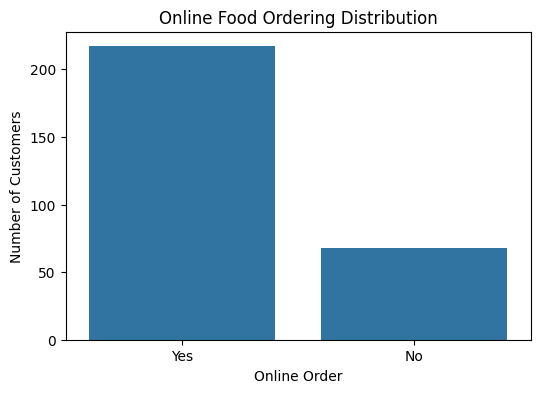

In [ ]:
print(df["Output"].value_counts())

plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Output")

plt.title("Online Food Ordering Distribution")
plt.xlabel("Online Order")
plt.ylabel("Number of Customers")

plt.show()


In [ ]:
X = df.drop(columns=["Output"])
y = df["Output"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'Customer Type', 'latitude', 'longitude', 'Pin code', 'Feedback']

Target:
Output


In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Family size', 'latitude', 'longitude', 'Pin code']

Categorical Features:
['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Customer Type', 'Feedback']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numeric_features)
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 228
Testing samples: 57


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (228, 29)
Testing data shape: (57, 29)


In [ ]:
df.to_csv("online_food_delivery_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
#1.RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [ ]:
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred = rf_model.predict(X_test_processed)

print("Predictions:")
print(y_pred)

Predictions:
['Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8245614035087719

Classification Report:
              precision    recall  f1-score   support

          No       0.67      0.57      0.62        14
         Yes       0.87      0.91      0.89        43

    accuracy                           0.82        57
   macro avg       0.77      0.74      0.75        57
weighted avg       0.82      0.82      0.82        57



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 8  6]
 [ 4 39]]


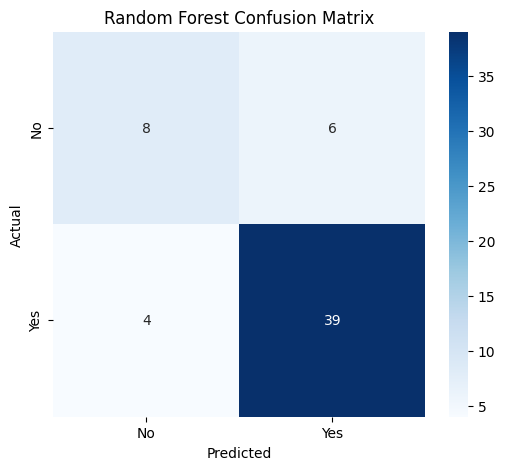

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
feature_names = preprocessor.get_feature_names_out()

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                                              Feature  Importance
22                     categorical__Feedback_Negative    0.143678
27                               numerical__longitude    0.107763
23                     categorical__Feedback_Positive    0.107080
26                                numerical__latitude    0.103480
28                                numerical__Pin code    0.092365
24                                     numerical__Age    0.084416
25                             numerical__Family size    0.051753
8                     categorical__Occupation_Student    0.024383
4                  categorical__Marital Status_Single    0.024302
14   categorical__Educational Qualifications_Graduate    0.020001
5                    categorical__Occupation_Employee    0.019529
0                          categorical__Gender_Female    0.018247
16  categorical__Educational Qualifications_Post G...    0.017887
1                            categorical__Gender_Male    0.017471
19        

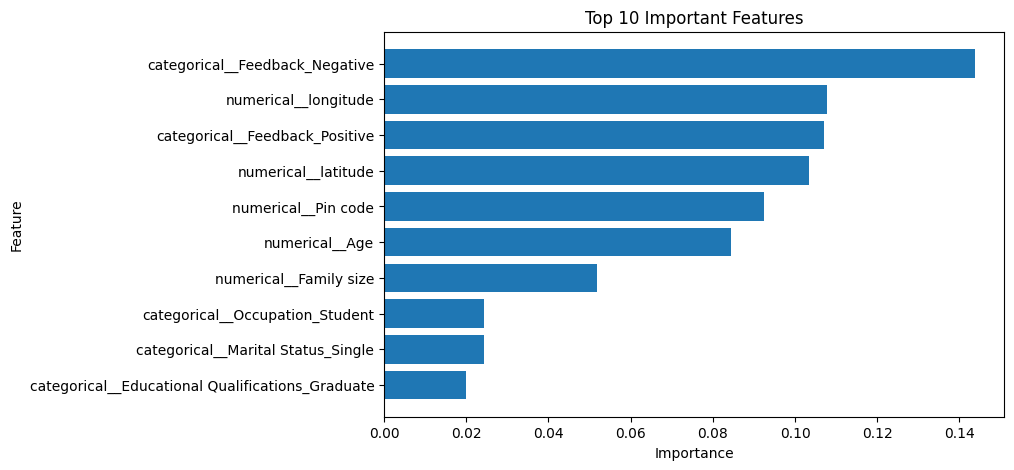

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(8,5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
#2. DEECISION TREE

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

In [ ]:
dt_model.fit(X_train_processed, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
y_pred_dt = dt_model.predict(X_test_processed)

print("Predictions:")
print(y_pred_dt)

Predictions:
['Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes']


In [ ]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7543859649122807


In [ ]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report:
              precision    recall  f1-score   support

          No       0.50      0.57      0.53        14
         Yes       0.85      0.81      0.83        43

    accuracy                           0.75        57
   macro avg       0.68      0.69      0.68        57
weighted avg       0.77      0.75      0.76        57



In [ ]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[ 8  6]
 [ 8 35]]


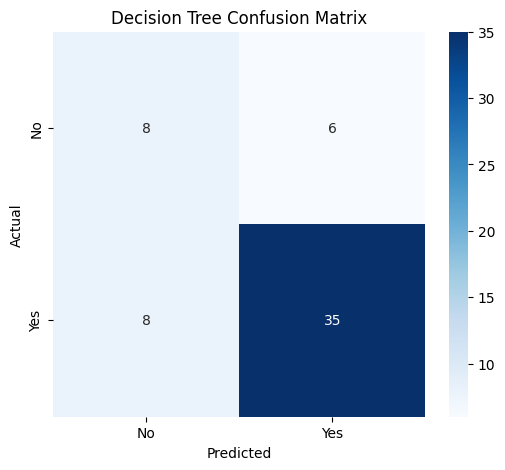

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

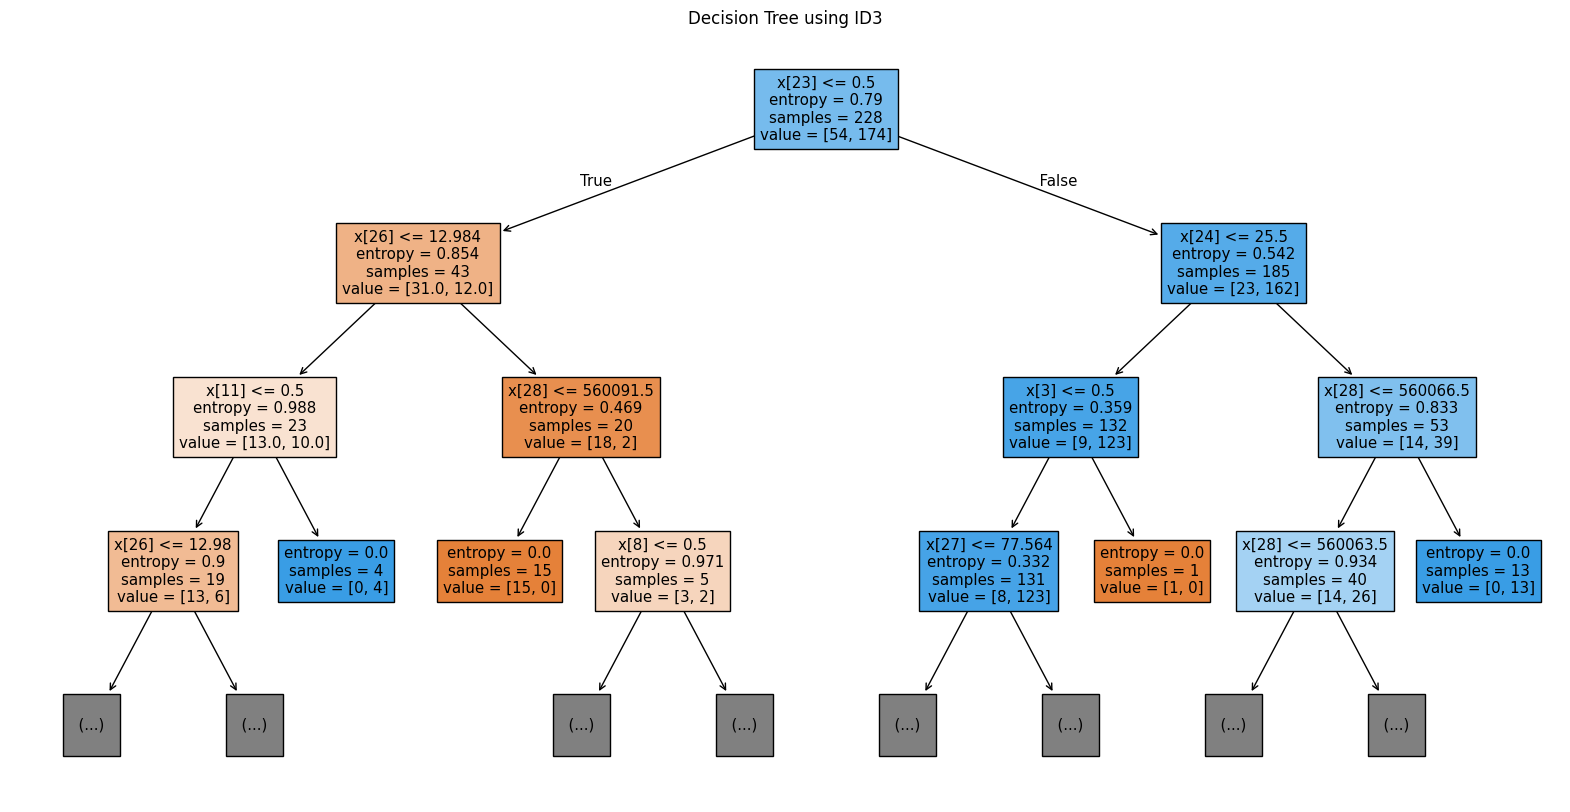

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt_model,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree using ID3")
plt.show()

In [ ]:
feature_names = preprocessor.get_feature_names_out()

dt_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": dt_model.feature_importances_
})

dt_importance = dt_importance.sort_values(
    by="Importance",
    ascending=False
)

print(dt_importance.head(10))

                                       Feature  Importance
23              categorical__Feedback_Positive    0.239500
28                         numerical__Pin code    0.161639
24                              numerical__Age    0.099118
27                        numerical__longitude    0.097785
25                      numerical__Family size    0.096566
26                         numerical__latitude    0.085349
11  categorical__Monthly Income_Below Rs.10000    0.041076
4           categorical__Marital Status_Single    0.040787
9   categorical__Monthly Income_10001 to 25000    0.040454
8              categorical__Occupation_Student    0.026961


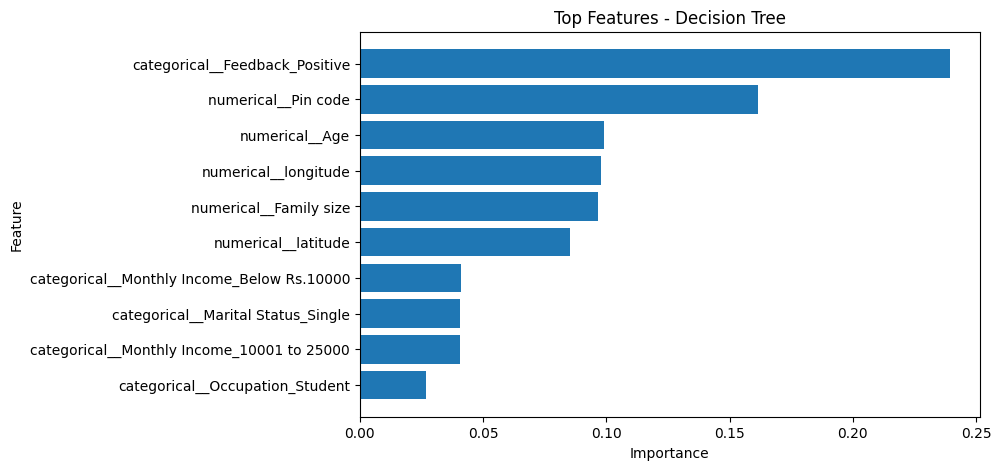

In [ ]:
top_dt_features = dt_importance.head(10)

plt.figure(figsize=(8,5))

plt.barh(
    top_dt_features["Feature"],
    top_dt_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features - Decision Tree")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# 3.SVC

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [ ]:
svm_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numeric_features
        )
    ]
)

In [ ]:
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
X_train_svm_processed = svm_preprocessor.fit_transform(X_train_svm)

X_test_svm_processed = svm_preprocessor.transform(X_test_svm)

print("Training shape:", X_train_svm_processed.shape)
print("Testing shape:", X_test_svm_processed.shape)

Training shape: (228, 29)
Testing shape: (57, 29)


In [ ]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

In [ ]:
svm_model.fit(
    X_train_svm_processed,
    y_train_svm
)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
y_pred_svm = svm_model.predict(X_test_svm_processed)

print("SVM Predictions:")
print(y_pred_svm)

SVM Predictions:
['Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes']


In [ ]:
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(
    y_test_svm,
    y_pred_svm
)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.8245614035087719


In [ ]:
from sklearn.metrics import classification_report

print("SVM Classification Report:")

print(
    classification_report(
        y_test_svm,
        y_pred_svm
    )
)

SVM Classification Report:
              precision    recall  f1-score   support

          No       0.67      0.57      0.62        14
         Yes       0.87      0.91      0.89        43

    accuracy                           0.82        57
   macro avg       0.77      0.74      0.75        57
weighted avg       0.82      0.82      0.82        57



In [ ]:
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(
    y_test_svm,
    y_pred_svm
)

print("SVM Confusion Matrix:")
print(cm_svm)

SVM Confusion Matrix:
[[ 8  6]
 [ 4 39]]


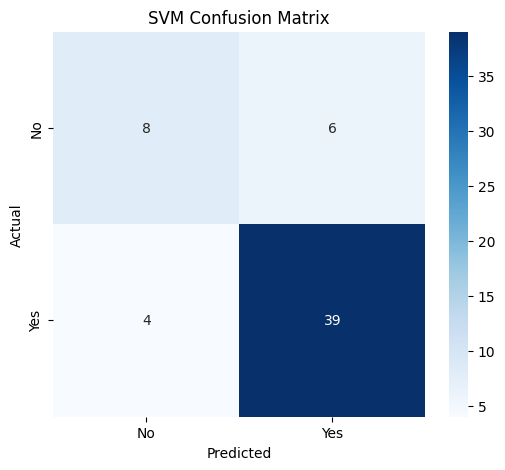

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()